# Real EEG to a distributed vector current field


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `eeg_volume_current_imaging` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：measurements (1, 64, 1600) float64：Native calibrated EEG potentials inV; electrode then time order；lead_field (1, 64, 789) float64：Independent conductor response inV/(A m); columns node-major then x/y/z；positions (1, 263, 3) float64：Source-node x/y/z coordinates in m, approximate head frame；electrodes (1, 64, 3) float64：Template electrode x/y/z coordinates in m, same frame and row order as potentials；times (1, 1600) float64：Time from the recording start in s。恢复目标：263空间节点三分量电流偶极矩，A m。

获取模型：平均参考投影后的lead-field线性体导模型将空间电流映射为EEG电位。实际恢复算法：solvers.reconstruct：显式SVD、trace归一化minimum-norm/Tikhonov逆。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:15没有独立生物空间真值；模板lead field是校准，baseline是方法结果。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：eeg_volume_current_imaging.ipynb单元4：5. Results；eeg_volume_current_imaging.ipynb单元6有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元5, 6（从0计数）。代码单元3个，带execution_count的3个，保存PNG输出3幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：原始方法参考只做数值比较，未直接绘制reference电流场；现有EEG观测/forward/current和正则敏感性图保留。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Reconstruct a spatial vector current distribution from real scalp EEG potentials despite the strong spatial ambiguity of volume conduction.

The bound first10seconds of a real64-electrode motor-imagery recording are reconstructed actively. An independently defined spherical conductor and template montage supply the lead-field calibration; no anatomical truth or task-specific weights are available. This is a full263-node3-component source distribution, not a class label or a best-fitting single dipole.


## 2. Data

| Key | Shape | Dtype | Description |
|---|---|---|---|
| measurements | (1, 64, 1600) | float64 | Native calibrated EEG potentials inV; electrode then time order |
| lead_field | (1, 64, 789) | float64 | Independent conductor response inV/(A m); columns node-major then x/y/z |
| positions | (1, 263, 3) | float64 | Source-node x/y/z coordinates in m, approximate head frame |
| electrodes | (1, 64, 3) | float64 | Template electrode x/y/z coordinates in m, same frame and row order as potentials |
| times | (1, 1600) | float64 | Time from the recording start in s |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Sampling rate | 160 | Hz | Original recording sampling frequency |
| Bound interval | 0 through 9.99375 | s | First 1600 samples; no temporal decimation |
| Electrode count | 64 | channel | Complete measured EEG channels, original order |
| Experimental run | subject001, run04 | identifier | Imagined unilateral fist movement protocol; segment may include rest |
| Montage | standard1005 template matched to original10-10 labels | dimensionless | Approximate coordinates, no individual digitization |
| Conductor center | (0,0,0.04) | m | Independent spherical head-model center |
| Outer radius | 0.09 | m | Spherical scalp radius |
| Shell relative radii | 0.90,0.92,0.97,1.0 | dimensionless | Four-shell geometry |
| Shell conductivities | 0.33,1.0,0.004,0.33 | S/m | Independent conductivity approximation |
| Source grid pitch | 0.015 | m | Cartesian spatial sampling |
| Source sphere radius | 0.065 | m | Candidate source-volume radius |
| Source center exclusion | 0.010 | m | Fixed minimum radial source distance |
| Source boundary clearance | 0.005 | m | Source sphere boundary margin |
| Reference | arithmetic electrode average | V | P removes the unobservable potential offset |
| Boundary model | quasi-static four-shell sphere in insulating exterior | dimensionless | No individual MRI anatomy assumed |
| Noise variance | not independently measured | unavailable | Regularization uses an explicitly assumed isotropic covariance, not a measured calibration |


## 3. Physics

The observations are the first ten seconds of subject001run04 in a real motor-imagery recording. Recover a three-component dipole-moment field at all 263 supplied spatial locations and all 1600sampled times. The acquisition model is


$$
\mathbf y(t)=\mathbf G\mathbf j(t)+\boldsymbol\eta(t),\qquad
\mathbf P=\mathbf I-\mathbf1\mathbf1^T/64,
\qquad \mathbf P\mathbf y(t)=\mathbf P\mathbf G\mathbf j(t)+\mathbf P\boldsymbol\eta(t).
$$


y contains 64 electrode potentials inV, j stacks Cartesian dipole moments inA m for263locations, G is the independent volume-conductor lead field inV/(A m), eta is measurement/model error, t is time, I the64×64 identity and1 the all-ones vector. P enforces an average reference and removes the unobservable constant potential. The supplied lead field was computed from an independently defined four-shell spherical approximation and template electrode positions; it was not fitted using a hidden source answer. The grid is a volume approximation, not an individual cortical surface. There are substantially more source components than independent electrodes, so this spatial inverse requires a prior and does not determine a unique biological truth.


## 4. Method

### Physics and inverse
Quasi-static volume conduction gives y(t)=G j(t)+noise, where y is64electrode potentials inV, j stacks263vector dipole moments inA m, and G is the independent lead field inV/(A m). Average-reference projection P removes the unobservable constant potential. An isotropic current prior and quadratic regularization make this highly nonunique spatial inverse identifiable as a standard minimum-norm estimate. The local SVD solves (AᵀA+lambda²qI)j=AᵀPy/sigma, A=PG/sigma, q=norm(A)²/63. All components/timepoints are judged without fitting alignment.

The three figure groups compare actual measurements and fresh predictions, the full spatial current distribution, and an actively reconstructed five-setting regularization sweep.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
%matplotlib inline
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import run_experiments,make_figures
data=load_data(root/'data/raw_data.npz')
with np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as f: upstream={k:f[k].copy() for k in f.files}
start=time.perf_counter()
experiments=run_experiments(data,upstream)
print(json.dumps({'fresh_runtime_s':time.perf_counter()-start,**experiments['metrics']},indent=2))

{
  "fresh_runtime_s": 0.06619449999925564,
  "upstream_relative_l2": 5.200506877392333e-15,
  "observation_residual": 0.44808488607527036,
  "explained_variance": 0.7992199348709119
}


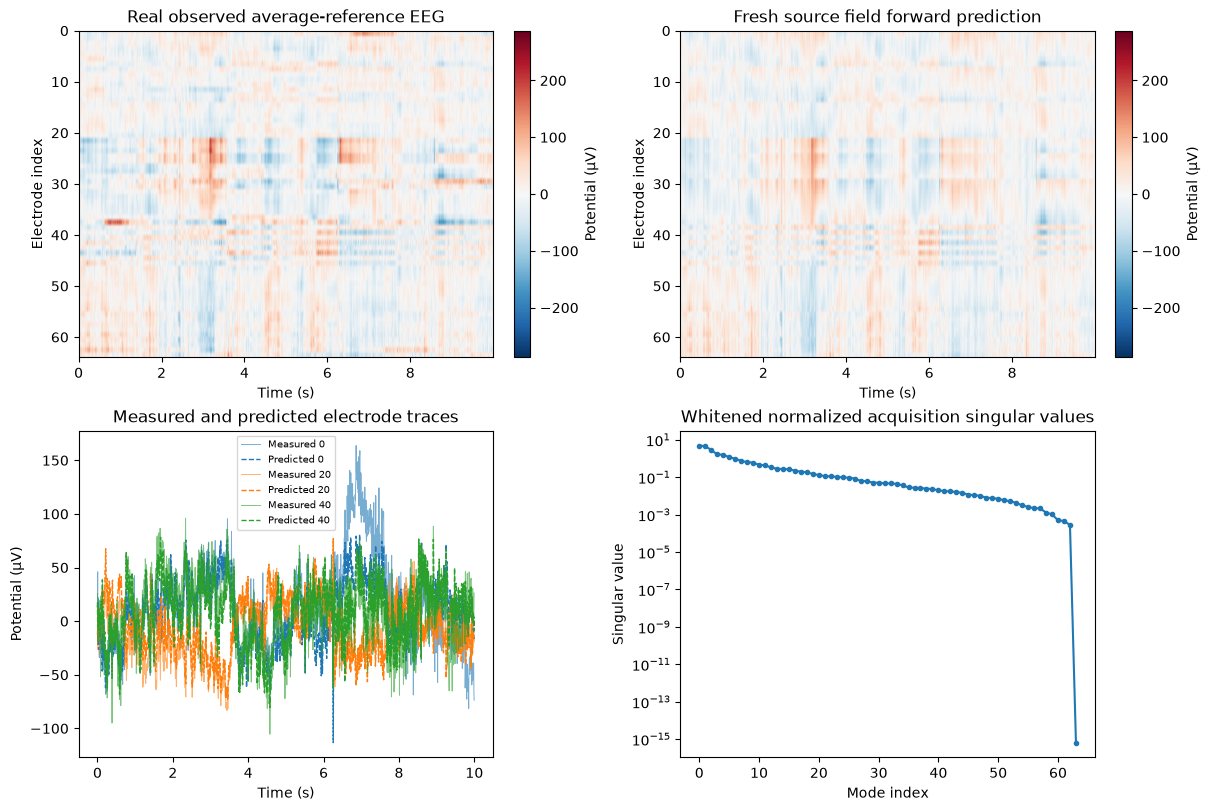

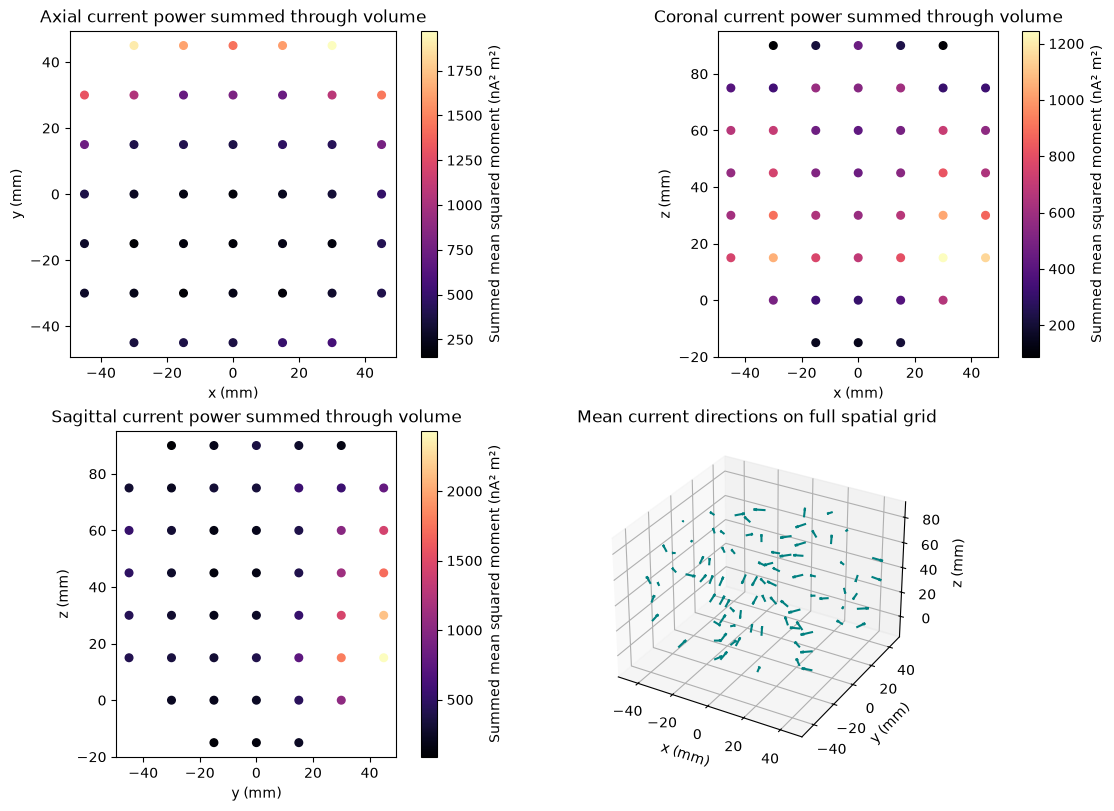

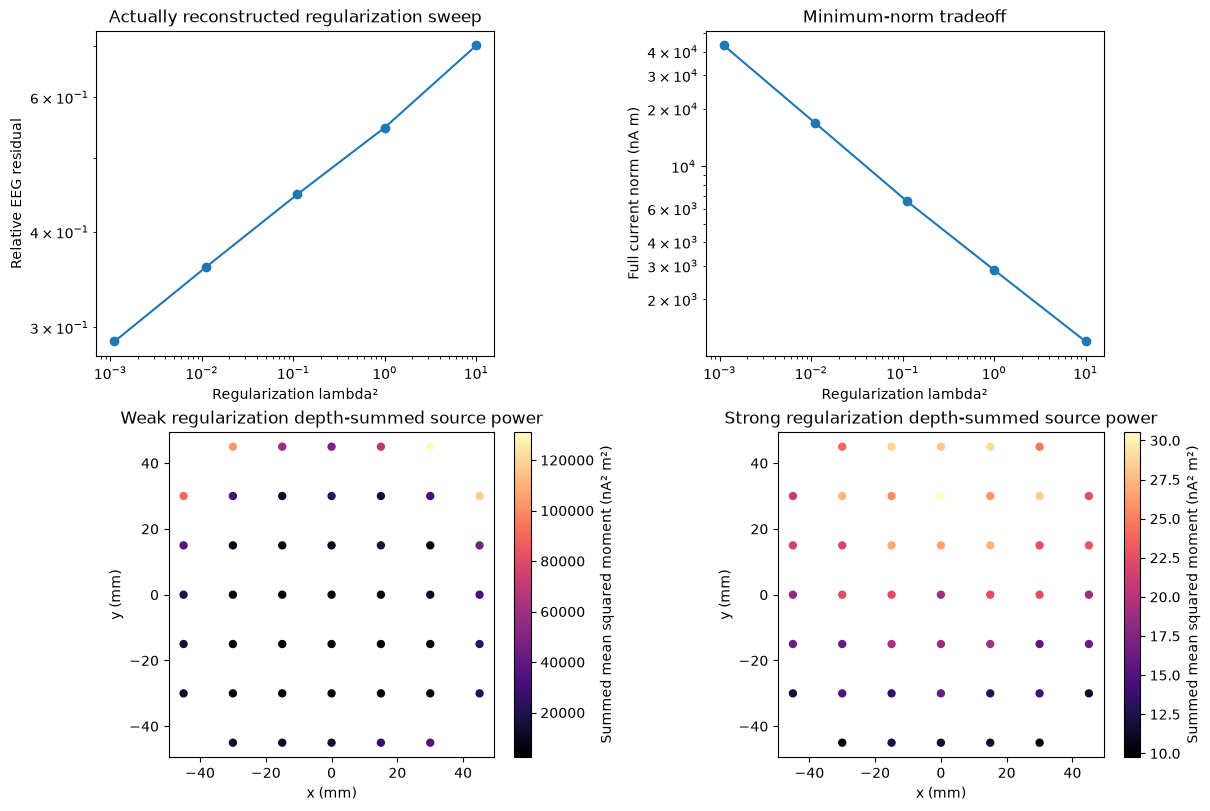

In [2]:
figures=make_figures(data,experiments)
for fig in figures:
    display(fig)
    plt.close(fig)

### Interpretation

The local field agrees with an independent original MNE minimum-norm run. Forward residual and the regularization sweep quantify fit versus current norm. The spherical anatomy, template electrode geometry, ad-hoc10µV covariance and isotropic source prior limit localization accuracy. This is a reproducible approximate biophysical source-field inverse, not a claim that template nodes identify true anatomical activation. All plots are freshly computed.


The following separately identified cleaned-run measurements are frozen scalar results from this task’s fresh local experiment run. The active reconstruction above remains the source of every plotted result; this archive records numeric provenance rather than supplying a reconstruction.


In [3]:
with np.load(root / 'notebooks/reference_outputs/cleaned_metrics.npz', allow_pickle=False) as recorded:
    print('Separately archived fresh cleaned-run measurements:', {k: recorded[k].tolist() for k in recorded.files})


Separately archived fresh cleaned-run measurements: {'upstream_relative_l2': 5.200506877392333e-15, 'observation_residual': 0.44808488607527036, 'explained_variance': 0.7992199348709119}


## 6. Conclusion

The 263-node three-component current field is one minimum-norm explanation of 64 average-referenced channels. The regularization sweep trades current norm against voltage residual; template electrodes, a spherical conductor and ad-hoc covariance limit anatomical localization.
